<a href="https://colab.research.google.com/github/govardhansnair/binomial-option-pricing-framework/blob/main/Binomial_model_Concept.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Stock information
S0=100
su=101
sd=99

#Option Information
K=100

#Calculate call option payoff
Cu=max(su-K,0)
Cd=max(sd-K,0)

print("Upward payoff: ",Cu)
print("Downward payoff: ",Cd)

#Calculate Delta Hedge
Delta=(Cu-Cd)/(su-sd)
print("Delta: ",Delta)

import math

#Risk Free rate and time
r=0
T=1

#Calculate bond position
beta=math.exp(-r*T)*((su*Cd-sd*Cu)/(su-sd))
print("Bond position: ",beta)

#Calculate option price
C0=Delta*S0+beta
print("Fair call option price: ",C0)

#Replicating portfolio payoff

portfolio_up=Delta*su+beta
portfolio_down=Delta*sd+beta
print("Portfolio payoff when stock rises: ",portfolio_up)
print("Portfolio payoff when stock falss: ",portfolio_down)

#Risk Neutral Probability
p=(math.exp(r*T)*S0-sd)/(su-sd)

#Calculate option price using risk-neutral pricing
option_price=math.exp(-r*T)*(p*Cu+(1-p)*Cd)
print("Risk-neutral probability: ",p)
print("Option price:", option_price)

Upward payoff:  1
Downward payoff:  0
Delta:  0.5
Bond position:  -49.5
Fair call option price:  0.5
Portfolio payoff when stock rises:  1.0
Portfolio payoff when stock falss:  0.0
Risk-neutral probability:  0.5
Option price: 0.5


In [ ]:
s0=80
su=84
sd=76
k=79
r=0
T=1
U=max(su-k,0)
D=max(sd-k,0)
print(U)
print(D)
Delta=(U-D)/(su-sd)
print(Delta)
import math
beta=math.exp(-r*T)*((su*D-sd*U)/(su-sd))
print(beta)
f=Delta*s0+beta
print(f)
p=(math.exp(r*T)*s0-D)/(U-D)
option_price=math.exp(-r*T)*(p*U+(1-p)*D)
print(option_price)

5
0
0.625
-47.5
2.5
80.0


In [ ]:
#CRR Binomial Option Pricing Engine
import numpy as np
import math

#1.Define Inputs
s0=100
k=100
r=0.05
sigma=0.20
T=1
N=3 #Number of time steps

# Calculate Time Interval
dt=T/N

# Calculate up and down movement
u=math.exp(sigma*math.sqrt(dt))
d=1/u

# Calculate risk-neutral probability
q=(math.exp(r*dt)-d)/(u-d)

# Calculate stock prices at maturity
stock_prices=[]
for j in range(N+1):
  price=s0*(u**j)*(d**(N-j)) # Gives the stock price at each step in the tree(fu,fd,fuu,fdd,fud...)
  stock_prices.append(price)

# Calculate call option payoffs
option_values=[]
for price in stock_prices:
  payoff=max(price-k,0)
  option_values.append(payoff)

# Work backwards through the tree

for step in range(N,0,-1):
  new_values=[]
  for j in range(step):
    value=math.exp(-r*dt)*(q*option_values[j+1]+(1-q)*option_values[j])
    new_values.append(value)
  option_values=new_values

# Display results

print("Upward factor: ",u)
print("Downward factor: ",d)
print("Risk-neutral probability: ",q)
print("Fair European call price: ",option_values[0])



Upward factor:  1.1224009024456676
Downward factor:  0.8909472522884107
Risk-neutral probability:  0.5437765963610321
Fair European call price:  11.043871091951113


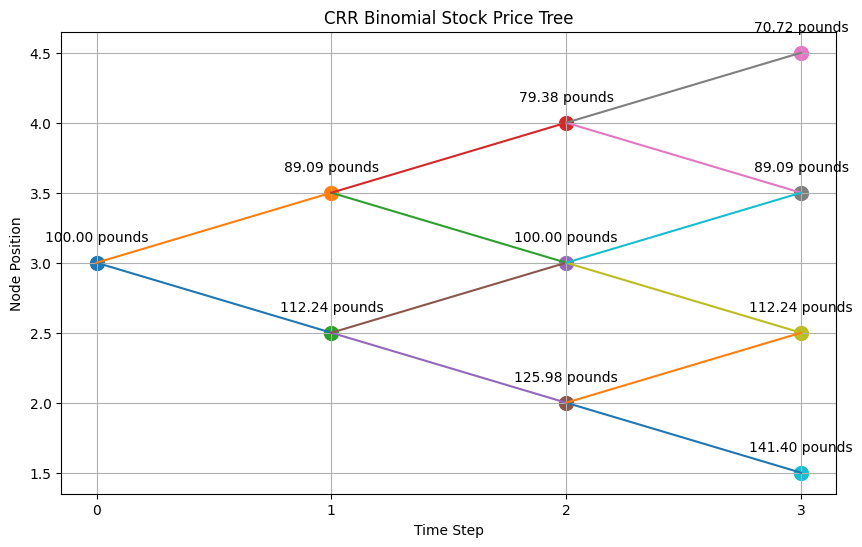

In [ ]:
import math
import matplotlib.pyplot as plt

s0=100
r=0.05
sigma=0.20
T=1
N=3

dt=T/N
u=math.exp(sigma*math.sqrt(dt))
d=1/u

plt.figure(figsize=(10,6)) # Creates blank graph where it is 10 inches in width and 6 inches in height

# Add stock prices at every node

for step in range(N+1):
  for j in range(step+1):
    price =s0*(u**j)*(d**(step-j)) # j is the number of upwards movements
    x=step
    y=N-j+(step/2)
    if step<N:  # Node lines
      x_next=step+1
      y_up=N-(j+1)+((step+1)/2)
      y_down=N-(j)+((step+1)/2)
      plt.plot([x,x_next],[y,y_up])
      plt.plot([x,x_next],[y,y_down])

    plt.scatter(x,y,s=100) # Places dot on the graph
    plt.text(x,y+0.15,f"{price:.2f} pounds",ha="center") # Adds Text to the graph

# Add graph labels
plt.title("CRR Binomial Stock Price Tree")
plt.xlabel("Time Step")
plt.ylabel("Node Position")
plt.xticks(range(N+1))
plt.grid()
plt.show()



In [ ]:
import math
import numpy as np
k=100
premium=8
stock_prices=[90,100,115,130]
for price in stock_prices:
  payoff=max(price-k,0)
  profit=payoff-premium
  breakeven=k+premium
  print("Breakeven: ",breakeven)
  print("Share price: ",price)
  print("Payoff: ",payoff)
  print("Profit: ",profit)
  print("------------------")




Breakeven:  108
Share price:  90
Payoff:  0
Profit:  -8
------------------
Breakeven:  108
Share price:  100
Payoff:  0
Profit:  -8
------------------
Breakeven:  108
Share price:  115
Payoff:  15
Profit:  7
------------------
Breakeven:  108
Share price:  130
Payoff:  30
Profit:  22
------------------


In [ ]:
def call_option_calculator(K,premium,stock_prices):
  payoff=max(stock_prices-K,0)
  profit=payoff-premium
  breakeven=K+premium
  return payoff,profit,breakeven
k=100
premium=8
stock_prices=[90,100,108,115,130]
for price in stock_prices:
  payoff,profit,breakeven =call_option_calculator(k,premium,price)
  print("Payoff: ",payoff)
  print("Profit: ",profit)
  print("Breakeven:",breakeven)
  print("--------------------")

Payoff:  0
Profit:  -8
Breakeven: 108
--------------------
Payoff:  0
Profit:  -8
Breakeven: 108
--------------------
Payoff:  8
Profit:  0
Breakeven: 108
--------------------
Payoff:  15
Profit:  7
Breakeven: 108
--------------------
Payoff:  30
Profit:  22
Breakeven: 108
--------------------


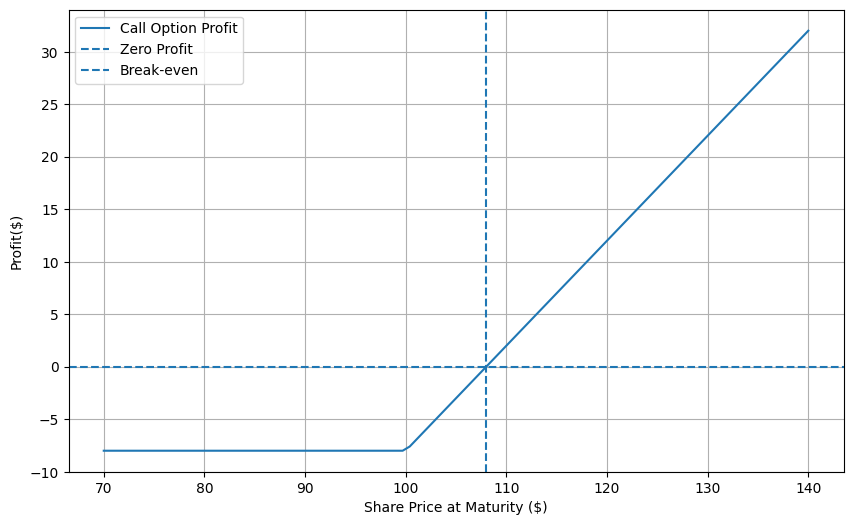

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

k=100
premium=8

stock_prices=np.linspace(70,140,100)

payoffs=np.maximum(stock_prices-k,0)

profits=payoffs-premium
breakeven=k+premium

plt.figure(figsize=(10,6))
plt.plot(stock_prices,profits,label="Call Option Profit") # Label gives the scale

plt.axhline(y=0,linestyle="--",label="Zero Profit") # Draws a horizontal line on graph
plt.axvline(x=breakeven,linestyle="--",label="Break-even") # Draws a vertical line on graph

plt.title=("Long Call Option Profit Diagram")
plt.xlabel("Share Price at Maturity ($)")
plt.ylabel("Profit($)")
plt.legend()
plt.grid()
plt.show()

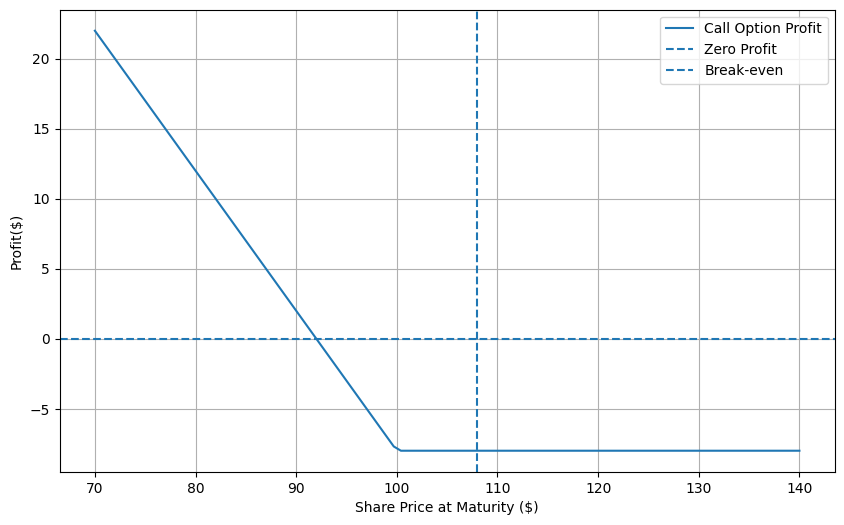

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

k=100
premium=8

stock_prices=np.linspace(70,140,100)

payoffs=np.maximum(k-stock_prices,0)

profits=payoffs-premium
breakeven=k+premium

plt.figure(figsize=(10,6))
plt.plot(stock_prices,profits,label="Call Option Profit") # Label gives the scale

plt.axhline(y=0,linestyle="--",label="Zero Profit") # Draws a horizontal line on graph
plt.axvline(x=breakeven,linestyle="--",label="Break-even") # Draws a vertical line on graph

plt.title=("Long Call Option Profit Diagram")
plt.xlabel("Share Price at Maturity ($)")
plt.ylabel("Profit($)")
plt.legend()
plt.grid()
plt.show()

In [ ]:
# Defining the tree values based on up and down movements
s0=100
u=1.2
d=0.8
N=2
stock_tree=[]
for step in range(N+1):
  prices=[]
  for j in range(step+1):
    price=s0*(u**j)*(d**(step-j))
    prices.append(price)
  stock_tree.append(prices)
print(stock_tree)

#Calculating Call payoffs
k=100
terminal_prices=stock_tree[-1]
call_payoff=[]
for price in terminal_prices:
  payoff=max(price-k,0)
  call_payoff.append(payoff)
print("Terminal stock prices: ",terminal_prices)
print("Call Payoffs: ",call_payoff)

#Calculating Put payoffs
k=100
terminal_price=stock_tree[-1]
put_payoff=[]
for price in terminal_price:
  payoffs=max(k-price,0)
  put_payoff.append(payoffs)
print("Terminal stock prices: ",terminal_price)
print("Put Payoffs: ",put_payoff)



[[100.0], [80.0, 120.0], [64.00000000000001, 96.0, 144.0]]
Terminal stock prices:  [64.00000000000001, 96.0, 144.0]
Call Payoffs:  [0, 0, 44.0]
Terminal stock prices:  [64.00000000000001, 96.0, 144.0]
Put Payoffs:  [35.999999999999986, 4.0, 0]


In [ ]:
# CRR BINOMIAL MODEL

import numpy as np
import math

# Define Inputs
s0=100
k=100
r=0.05
sigma=0.20
T=1
N=3

# Calculate time interval
dt=T/N

# Calculate upward and downward factors
u=(math.exp(sigma*math.sqrt(dt)))
d=1/u

# Calculate risk-neutral probability
q=(math.exp(r*dt)-d)/(u-d)

# Generate stock price tree
stock_tree=[]

for step in range(N+1):
  prices=[]
  for j in range(step+1):
    price=s0*(u**j)*(d**(step-j))
    prices.append(price)
  stock_tree.append(prices)


# Calculate terminal call payoffs
option_values=[]
for price in stock_tree[-1]:
  payoff=max(price-k,0)
  option_values.append(payoff)

# Work backwards through the tree
for step in range(N,0,-1):
  new_values=[]
  for j in range(step):
    value=math.exp(-r*dt)*(q*option_values[j+1]+(1-q)*option_values[j])
    new_values.append(value)
  option_values=new_values

# Display results
print("Upward factor: ",u)
print("Downward factor: ",d)
print("Risk-neutral probability: ",q)
print("Fair European call price: ",option_values[0])

Upward factor:  1.1224009024456676
Downward factor:  0.8909472522884107
Risk-neutral probability:  0.5437765963610321
Fair European call price:  11.043871091951113


In [ ]:
# Calculate Historical Volatility
prices=[100,102,101,105,103,108]

import numpy as np

prices=np.array(prices)
returns=np.log(prices[1:]/prices[:-1])
print("Log returns: ")
print(returns)
daily_volatility=np.std(returns,ddof=1) #Standard deviation
annual_volatility=daily_volatility*np.sqrt(252)
print("Daily volatility: ",daily_volatility)
print("Annual volatility: ",annual_volatility)

Log returns: 
[ 0.01980263 -0.0098523   0.03883983 -0.01923136  0.04740224]
Daily volatility:  0.029282937046754675
Annual volatility:  0.4648522144996383
